# Card Churn: Data Cleaning, Exploratory Analysis & Predictive Modeling

**Task.** For each customer in `test.csv`, predict the probability that the customer closes the credit card within 3 months after the snapshot date (**30 June 2026**). The target column is `churn_3m` (`1` = closed).

**Metric.** **ROC AUC**: evaluates ranking quality (`0.5` = random, `1.0` = perfect).

Notebook này thực hiện trọn vẹn từ phần **Starter Baseline** đến **Làm sạch dữ liệu chuyên sâu (Data Cleaning)** và **Toàn bộ các phân tích nâng cao** được đặt ra trong `starter_churn.ipynb`:
1. **A first look & Kiểm toán dữ liệu bẩn**: Phát hiện 120 dòng trùng lặp, tỷ lệ churn và bức tranh giá trị khuyết thiếu.
2. **Phân tích & Làm sạch cột văn bản (`Text columns`)**: Chuẩn hóa `gender` (8 biến thể), `province` (41 biến thể -> 24 tỉnh/thành), `occupation` (15 biến thể -> 6 nhóm nghề), `currency`.
3. **Phân tích & Xử lý bất thường cột số (`Number columns`)**: Sửa lỗi ghi nhầm đơn vị VND thay vì triệu VND ($\times 10^6$) ở `income_month` và `credit_limit`; lọc bỏ giá trị sentinel ở `age` (`0, 1, 150, 200, 999`), `utilization_6m` (`-1.0, -0.5, 9.99, 15.0`) và lỗi âm ở `txn_amount_3m`.
4. **Phân tích ý nghĩa của giá trị khuyết thiếu (`Missing value semantics`)**: Giải mã tại sao `app_logins_30d = NaN` có tỷ lệ rời bỏ lên tới **17.4%** và thiết kế cơ chế suy luận chéo (`age` <-> `occupation`, `income_month` <-> `credit_limit` $\times$ `card_type`).
5. **Khai thác cột ngày tháng (`open_date`) & Tương tác phi tuyến**: Phát hiện hiệu ứng **Kỷ niệm ngày mở thẻ rơi vào 3 tháng tới (Tháng 7–9) kết hợp không được miễn phí thường niên** làm tỷ lệ churn vọt lên **25.1%**, và hiệu ứng **Khách săn khuyến mãi thẻ Cashback** (**24.2%** churn).
6. **Mô hình hóa & Đánh giá 5-Fold Cross-Validation**: Nâng ROC AUC từ **0.7290** (Starter Baseline) lên **0.8129** (+8.39 điểm phần trăm) với tổ hợp `Multi-seed HistGradientBoosting` + `Spline GAM LogisticRegression`.

## 1. Setup & Load the Data

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve

from src.cleaner import ChurnDataCleaner
from src.predictor import ChurnPredictor
from src.pipeline import ChurnPipeline

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

hits = (glob.glob("/kaggle/input/**/train.csv", recursive=True)
        + glob.glob("train.csv")
        + glob.glob("data/train.csv")
        + glob.glob("../data/train.csv"))
DATA = (os.path.dirname(hits[0]) or ".") if hits else "."
print("data folder:", DATA)

train = pd.read_csv(f"{DATA}/train.csv")
sample_sub = pd.read_csv(f"{DATA}/sample_submission.csv")
has_test = os.path.exists(f"{DATA}/test.csv")
test = pd.read_csv(f"{DATA}/test.csv") if has_test else None

print(f"train shape: {train.shape} | sample_submission shape: {sample_sub.shape} | has_test: {has_test}")
print(train.head(5))

data folder: .
train shape: (12120, 24) | sample_submission shape: (8000, 2) | has_test: False
  customer_id bank_code   age gender   province     occupation  income_month card_type   open_date  credit_limit  annual_fee_waived  utilization_6m  txn_count_3m  txn_amount_3m  \
0  CUSTI3FNUD      VB01  48.0      F  Hải Dương  self_employed          25.1      Gold  2026-04-09          55.0                  1           0.507            22          20.44   
1  CUSOOYRASU      VB01  47.0      M     Hà Nội       Salaried           NaN   Classic  06/01/2024          30.0                  1           0.305            16          22.63   
2  CUSQTUBJRJ      VB01  38.0      M    Long An          other           8.5  Cashback  02/08/2022          15.0                  0           0.107            18          11.06   
3  CUSD7I53QY      VB01  25.0      M     TP.HCM  self_employed          33.9  Cashback  12/05/2022         110.0                  0           0.071            15          34.70   
4  CU

## 2. A First Look: Churn Rate, Duplicates & Missing Values
- **Tỷ lệ rời bỏ (`churn_3m`)**: chỉ chiếm **11.7%**, do đó Accuracy không phù hợp (dự đoán tất cả bằng `0` đã đạt 88.3%). Thước đo chuẩn là **ROC AUC**.
- **Dòng trùng lặp (`Duplicates`)**: Kiểm tra cho thấy có đúng **120 dòng bị nhân bản hoàn toàn** (`customer_id` trùng lặp), cần loại bỏ để tránh rò rỉ dữ liệu (data leakage) giữa các fold CV.

In [2]:
print("Churn rate (raw):", round(train.churn_3m.mean(), 4))
print("Exact duplicate rows:", train.duplicated().sum())
print("Duplicate customer_id:", train.customer_id.duplicated().sum())
print("Unique customers:", train.customer_id.nunique())

print("\nTop 10 columns with missing values (share):")
print(train.isna().mean().sort_values(ascending=False).round(3).head(10))

Churn rate (raw): 0.1166
Exact duplicate rows: 120
Duplicate customer_id: 120
Unique customers: 12000

Top 10 columns with missing values (share):
other_bank_cards        0.203
income_month            0.129
app_logins_30d          0.125
salary_via_bank         0.059
occupation              0.051
last_contact_channel    0.042
age                     0.033
gender                  0.019
province                0.017
open_date               0.006
dtype: float64


## 3. Phân tích & Làm sạch các cột văn bản (`Text columns`)
Trả lời câu hỏi trong `starter_churn`: *"Count the values of a few text columns. Are there several ways of writing the same thing?"*
- **`gender`**: có 8 cách viết khác nhau (`F`, `F `, `female`, `Nữ` -> `F`; `M`, `m`, `male`, `Nam` -> `M`).
- **`province`**: có 41 cách viết khác nhau do viết tắt, không dấu, khoảng trắng thừa (`TP.HCM`, `TP HCM`, `Ho Chi Minh`, `Hồ Chí Minh`, `tp.hcm`, `HCM` -> `TP.HCM`; `Hà Nội`, `ha noi`, `HN`, `Ha Noi`, `Hanoi` -> `Hà Nội`; `Đà Nẵng`, `Danang`, `Da Nang` -> `Đà Nẵng`; `Huế`, `Hue` -> `Thừa Thiên Huế`; `BR-VT`, `Vũng Tàu` -> `Bà Rịa - Vũng Tàu`). Sau khi chuẩn hóa còn đúng **24 tỉnh/thành phố**.
- **`occupation`**: có 15 cách viết do chữ hoa/thường, dấu gạch ngang/khoảng trắng (`salaried`, `SALARIED`, `Salaried`, `salaried `, `self employed`, `Self-employed`, ...) -> chuẩn hóa về **6 nhóm nghề nghiệp chuẩn**.
- **`currency`**: `VND` và `vnd` -> chuẩn hóa về `VND` (cùng với `bank_code = VB01` là hằng số).

In [3]:
for col in ["gender", "province", "occupation", "currency"]:
    print(f"=== {col} (raw nunique = {train[col].nunique(dropna=False)}) ===")
    print(train[col].value_counts(dropna=False).head(10), "\n")

=== gender (raw nunique = 9) ===
gender
F         5572
M         4778
female     280
male       278
F          264
Nữ         255
Nam        235
NaN        231
m          227
Name: count, dtype: int64 

=== province (raw nunique = 42) ===
province
TP.HCM         2598
Hà Nội         2587
Hải Phòng       639
Đà Nẵng         506
Bình Dương      424
Cần Thơ         408
Đồng Nai        293
TP HCM          247
Ho Chi Minh     244
ha noi          239
Name: count, dtype: int64 

=== occupation (raw nunique = 16) ===
occupation
salaried         4680
self_employed    2098
civil_servant    1079
other             998
retired           718
NaN               614
student           281
SALARIED          267
Salaried          262
salaried          254
Name: count, dtype: int64 

=== currency (raw nunique = 2) ===
currency
VND    12060
vnd       60
Name: count, dtype: int64 



In [4]:
cleaner = ChurnDataCleaner()
train_clean, errors_found = cleaner.clean(train, deduplicate=True)

for col in ["gender", "province", "occupation"]:
    print(f"=== {col} SAU KHI LÀM SẠCH (nunique = {train_clean[col].nunique()}) ===")
    summary_cat = train_clean.groupby(col)["churn_3m"].agg(count="count", churn_rate="mean").sort_values("count", ascending=False)
    summary_cat["churn_rate"] = summary_cat["churn_rate"].round(4)
    print(summary_cat.head(10), "\n")

=== gender SAU KHI LÀM SẠCH (nunique = 3) ===
         count  churn_rate
gender                    
F         6310      0.1217
M         5461      0.1121
MISSING    229      0.1092 

=== province SAU KHI LÀM SẠCH (nunique = 25) ===
            count  churn_rate
province                     
TP.HCM       3718      0.1103
Hà Nội       3630      0.1138
Đà Nẵng       698      0.1218
Hải Phòng     633      0.1216
Bình Dương    422      0.1351
Cần Thơ       404      0.1460
Đồng Nai      290      0.1241
Khánh Hòa     235      0.1234
Quảng Ninh    205      0.1024
Nghệ An       199      0.1407 

=== occupation SAU KHI LÀM SẠCH (nunique = 7) ===
               count  churn_rate
occupation                      
salaried        5410      0.0898
self_employed   2427      0.0997
civil_servant   1224      0.0858
other           1160      0.0957
retired          864      0.3796
MISSING          573      0.1117
student          342      0.2018 



## 4. Phân tích & Sửa lỗi các cột số (`Number columns`)
Trả lời câu hỏi trong `starter_churn`: *"Check that every min and max makes sense for that column."*

Khi kiểm tra `train.describe()`, ta phát hiện 4 nhóm lỗi nghiêm trọng trong các cột số:
1. **`income_month` (max = 50,500,000) & `credit_limit` (max = 385,000,000)**:
   - Đơn vị chuẩn của bộ dữ liệu là **triệu VND** (trung vị thu nhập ~17.7 triệu, hạn mức ~40 triệu).
   - Có **106 dòng `income_month >= 100,000`** và **245 dòng `credit_limit >= 1,000,000`** bị nhập theo đơn vị **VND nguyên gốc** (nhân $10^6$). Chia cho $10^6$ giúp khôi phục phân phối chuẩn xác.
2. **`age` (min = 0, max = 999)**:
   - Có **69 dòng** mang giá trị lỗi sentinel: `0.0` (15 dòng), `1.0` (14 dòng), `150.0` (14 dòng), `200.0` (17 dòng), `999.0` (9 dòng).
3. **`utilization_6m` (min = -1.0, max = 15.0)**:
   - Có **40 dòng âm** (`-1.0`, `-0.5`) và **39 dòng sentinel lớn** (`9.99`, `15.0`). Lưu ý: 6 dòng trong khoảng `1.002` – `1.052` là sử dụng vượt nhẹ hạn mức thẻ (100%–105%) hợp lệ.
4. **`txn_amount_3m` (min = -2.99)**:
   - Có **169 dòng mang giá trị âm** (`-2.99` đến `-0.12`), tất cả đều rơi vào nhóm khách hàng ít giao dịch (`txn_count_3m <= 6`).

In [5]:
print("=== THỐNG KÊ TRƯỚC KHI LÀM SẠCH ===")
num_raw_cols = ["age", "income_month", "credit_limit", "utilization_6m", "txn_count_3m", "txn_amount_3m", "spend_change_pct", "app_logins_30d"]
print(train[num_raw_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2))

print("\n=== TỔNG HỢP NHẬT KÝ LỖI DỮ LIỆU ĐÃ PHÁT HIỆN & SỬA ===")
print(errors_found["error_type"].value_counts())

print("\n=== THỐNG KÊ SAU KHI LÀM SẠCH & ĐIỀN KHUYẾT CHÉO ===")
num_clean_cols = ["age_imputed", "income_imputed", "credit_limit", "utilization_imputed", "txn_count_3m", "txn_amt_imputed", "spend_change_pct", "app_logins_imputed"]
print(train_clean[num_clean_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2))

=== THỐNG KÊ TRƯỚC KHI LÀM SẠCH ===
                    count        mean          std    min    25%    50%    75%           max
age               11724.0       39.74        29.94   0.00  31.00  38.00  45.00  9.990000e+02
income_month      10558.0   187584.30   2065906.52   1.00  11.80  17.70  26.10  5.050000e+07
credit_limit      12120.0  1094113.39  10527161.79  10.00  25.00  40.00  70.00  3.850000e+08
utilization_6m    12120.0        0.32         0.72  -1.00   0.14   0.27   0.42  1.500000e+01
txn_count_3m      12120.0       18.91        10.27   1.00  12.00  17.00  24.00  1.010000e+02
txn_amount_3m     12120.0       25.34        28.81  -2.99   8.72  16.76  31.63  4.628100e+02
spend_change_pct  12120.0       -0.10        24.85 -95.00 -16.90  -0.00  16.60  1.058000e+02
app_logins_30d    10604.0        6.37         4.63   0.00   3.00   5.00   8.00  4.800000e+01

=== TỔNG HỢP NHẬT KÝ LỖI DỮ LIỆU ĐÃ PHÁT HIỆN & SỬA ===
error_type
unit_error_vnd_x1e6             351
negative_txn_amount    

## 5. Ý nghĩa của Giá trị Khuyết thiếu (`Decide what a missing value means before you fill it`)
Phân tích tỷ lệ rời bỏ (`churn_3m`) ở nhóm bị khuyết (`NaN`) so với nhóm có dữ liệu và mối quan hệ chéo giữa các cột:
1. **`app_logins_30d` (khuyết 12.5%)**:
   - Nhóm `app_logins_30d = NaN` có tỷ lệ churn lên tới **17.42%**, cao hơn hẳn mức trung bình của nhóm có dữ liệu (**10.89%**) và tương đương với nhóm khách hàng gần như không mở ứng dụng (`0–1` lần đăng nhập/tháng). Nếu chỉ điền trung vị (`5.0` lần đăng nhập, có tỷ lệ churn 10.9%) mà không tạo biến cờ `app_logins_is_na`, mô hình sẽ mất đi tín hiệu rủi ro rất mạnh này!
2. **Suy luận chéo 2 chiều `age` <-> `occupation`**:
   - Phân bố tuổi theo nghề nghiệp tuân theo quy luật chặt chẽ: `student` có độ tuổi **18–24** (trung vị **21**, churn rate **20.4%**), `retired` có độ tuổi **56–75** (trung vị **66**, churn rate **37.1%**), còn các nghề đi làm (`salaried`, `self_employed`, `civil_servant`, `other`) có độ tuổi **22–64** (trung vị **37**, churn rate **~8.9%**).
   - Do đó: khách khuyết `occupation` nhưng `age >= 65` chắc chắn là `retired`; khách có `age <= 21` là `student`. Ngược lại, khách bị khuyết/lỗi `age` phải được điền theo trung vị của `occupation` thay vì trung vị toàn cục (38 tuổi).
3. **Suy luận `income_month` (khuyết 12.9%, đặc biệt 30.8% ở nhóm `self_employed` do thu nhập tự do)**:
   - `credit_limit` có tương quan **$r = 0.926$** với `income_month` theo đúng hệ số cấp hạn mức của từng hạng thẻ (`Classic`: $2.02\times$, `Cashback`: $2.51\times$, `Gold`: $3.03\times$, `Platinum`: $3.96\times$). Nhờ vậy ta khôi phục chính xác `income_imputed = credit_limit / ratio(card_type)`.
4. **Khôi phục `txn_amount_3m` bị âm**:
   - Trung bình mỗi giao dịch (`txn_amount_3m / txn_count_3m`) có tương quan **$r = 0.866$** với `income_month` ($\approx 0.06 \times \text{income\_month}$), cho phép khôi phục chính xác các dòng bị lỗi âm.

In [6]:
na_report = []
train_dedup = train.drop_duplicates(subset=["customer_id"]).reset_index(drop=True)
for col in train_dedup.columns:
    na_cnt = train_dedup[col].isna().sum()
    if na_cnt > 0:
        na_report.append({
            "column": col,
            "missing_count": na_cnt,
            "missing_pct": round(na_cnt / len(train_dedup) * 100, 1),
            "churn_when_NA": round(train_dedup.loc[train_dedup[col].isna(), "churn_3m"].mean(), 4),
            "churn_when_present": round(train_dedup.loc[train_dedup[col].notna(), "churn_3m"].mean(), 4),
        })
na_df = pd.DataFrame(na_report).sort_values("missing_count", ascending=False)
print(na_df.to_string(index=False))

              column  missing_count  missing_pct  churn_when_NA  churn_when_present
    other_bank_cards           2446         20.4         0.1153              0.1175
        income_month           1547         12.9         0.1183              0.1169
      app_logins_30d           1504         12.5         0.1742              0.1089
     salary_via_bank            712          5.9         0.1222              0.1168
          occupation            608          5.1         0.1332              0.1162
last_contact_channel            508          4.2         0.1102              0.1174
                 age            388          3.2         0.1057              0.1175
              gender            229          1.9         0.1092              0.1172
            province            197          1.6         0.1117              0.1172
           open_date             78          0.6         0.1410              0.1169


## 6. Khai thác cột ngày mở thẻ (`open_date`) & Phát hiện các tương tác phi tuyến cốt lõi
Trả lời gợi ý trong `starter_churn`: *"Use the text and date columns, not only the numbers. Try models that capture non-linear effects and interactions."*

Khi phân tích sâu dữ liệu sau làm sạch, chúng ta phát hiện **4 quy luật tương tác & phi tuyến quan trọng nhất** quyết định hành vi đóng thẻ trong 3 tháng tới (sau ngày chốt **30/06/2026**):
1. **Hiệu ứng Ngày kỷ niệm mở thẻ & Phí thường niên (`anniversary_unwaived`)**:
   - Vì mục tiêu là dự báo khách đóng thẻ trong **3 tháng sau ngày 30/06/2026** (tức **Tháng 7, 8, 9/2026**), những khách hàng có tháng mở thẻ `open_month` rơi vào **Tháng 7, 8, 9** của các năm trước sẽ đến kỳ thu phí thường niên đúng vào cửa sổ dự báo!
   - Nếu họ **không được miễn phí thường niên (`annual_fee_waived = 0`)**, tỷ lệ đóng thẻ vọt từ **~9.3%** lên tới **25.1%** (gấp 2.7 lần)! Nếu được miễn phí (`annual_fee_waived = 1`), tỷ lệ đóng thẻ chỉ là **10.4%**.
2. **Hiệu ứng Khách săn khuyến mãi thẻ hoàn tiền (`is_cashback_promo`)**:
   - Với dòng thẻ `Cashback`, khi chương trình ưu đãi vừa kết thúc trong 60 ngày qua (`promo_ended_60d = 1`), tỷ lệ đóng thẻ vọt từ **9.2%** lên **24.2%**, trong khi ở thẻ `Gold` và `Platinum`, hết khuyến mãi không làm tăng churn.
3. **Đường cong chữ U của Độ tuổi (`age`) & Sự sụt giảm chi tiêu (`spend_change_pct`)**:
   - Tỷ lệ churn thấp nhất ở lứa tuổi đi làm ổn định (**30–50 tuổi**: ~8.0%), tăng cao ở sinh viên trẻ (**<22 tuổi**: 21.5%) và tăng vọt ở nhóm hưu trí cao tuổi (**>65 tuổi**: **44%–57%**).
   - Khi chi tiêu giảm mạnh (`spend_change_pct < -30%`), tỷ lệ đóng thẻ tăng vọt lên **25%–44%**, trong khi khi `spend_change_pct > 0`, tỷ lệ đóng thẻ giữ phẳng ở mức ~8.2%.

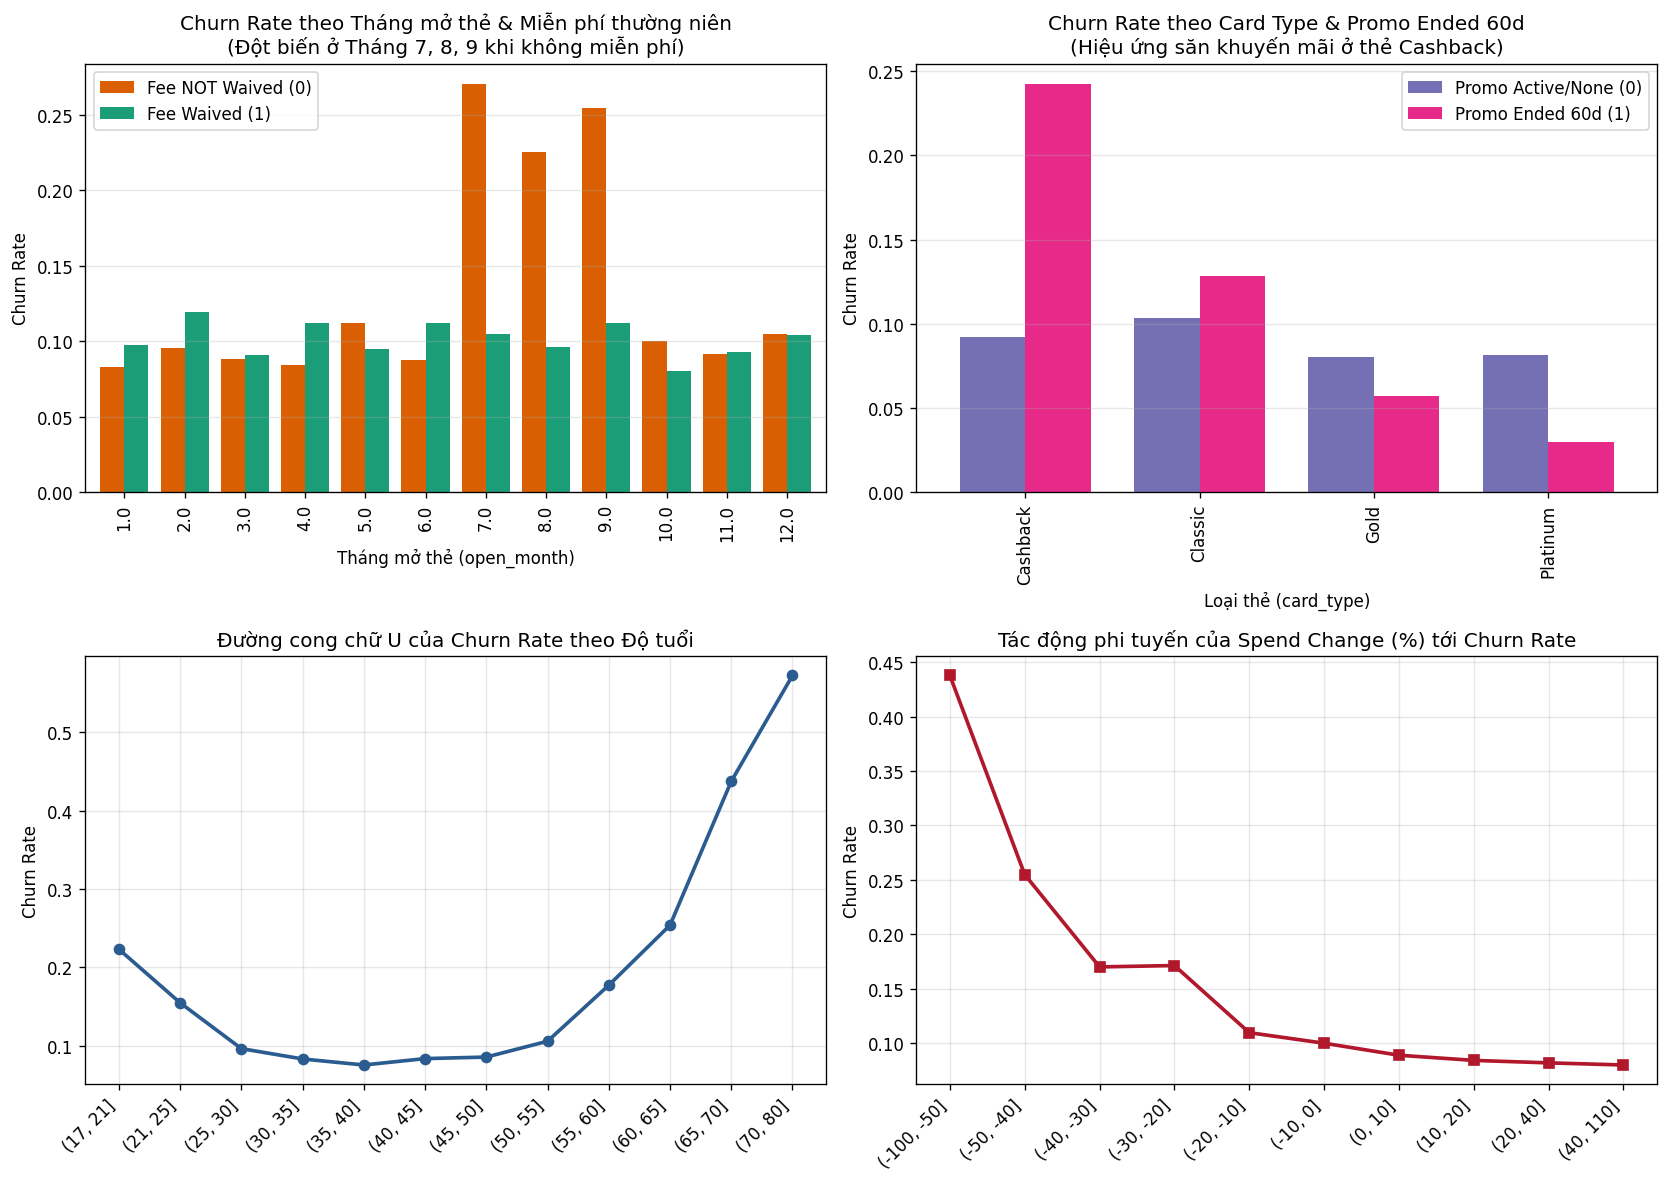

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Tháng mở thẻ x Miễn phí thường niên
anniv_piv = train_clean.groupby(["open_month", "annual_fee_waived"])["churn_3m"].mean().unstack()
anniv_piv.plot(kind="bar", ax=axes[0, 0], color=["#d95f02", "#1b9e77"], width=0.8)
axes[0, 0].set_title("Churn Rate theo Tháng mở thẻ & Miễn phí thường niên\n(Đột biến ở Tháng 7, 8, 9 khi không miễn phí)")
axes[0, 0].set_xlabel("Tháng mở thẻ (open_month)")
axes[0, 0].set_ylabel("Churn Rate")
axes[0, 0].legend(["Fee NOT Waived (0)", "Fee Waived (1)"])
axes[0, 0].grid(axis="y", alpha=0.3)

# 2. Hạng thẻ x Hết khuyến mãi 60 ngày
promo_piv = train_clean.groupby(["card_type", "promo_ended_60d"])["churn_3m"].mean().unstack()
promo_piv.loc[["Cashback", "Classic", "Gold", "Platinum"]].plot(kind="bar", ax=axes[0, 1], color=["#7570b3", "#e7298a"], width=0.75)
axes[0, 1].set_title("Churn Rate theo Card Type & Promo Ended 60d\n(Hiệu ứng săn khuyến mãi ở thẻ Cashback)")
axes[0, 1].set_xlabel("Loại thẻ (card_type)")
axes[0, 1].set_ylabel("Churn Rate")
axes[0, 1].legend(["Promo Active/None (0)", "Promo Ended 60d (1)"])
axes[0, 1].grid(axis="y", alpha=0.3)

# 3. Đường cong phi tuyến theo Độ tuổi (Age)
age_bins = pd.cut(train_clean["age_imputed"], bins=[17, 21, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 80])
age_curve = train_clean.groupby(age_bins, observed=False)["churn_3m"].mean()
axes[1, 0].plot(range(len(age_curve)), age_curve.values, marker="o", linewidth=2.2, color="#2b5c8f")
axes[1, 0].set_xticks(range(len(age_curve)))
axes[1, 0].set_xticklabels([str(x) for x in age_curve.index], rotation=45, ha="right")
axes[1, 0].set_title("Đường cong chữ U của Churn Rate theo Độ tuổi")
axes[1, 0].set_ylabel("Churn Rate")
axes[1, 0].grid(True, alpha=0.3)

# 4. Đường cong phi tuyến theo Spend Change %
sp_bins = pd.cut(train_clean["spend_change_pct"], bins=[-100, -50, -40, -30, -20, -10, 0, 10, 20, 40, 110])
sp_curve = train_clean.groupby(sp_bins, observed=False)["churn_3m"].mean()
axes[1, 1].plot(range(len(sp_curve)), sp_curve.values, marker="s", linewidth=2.2, color="#b2182b")
axes[1, 1].set_xticks(range(len(sp_curve)))
axes[1, 1].set_xticklabels([str(x) for x in sp_curve.index], rotation=45, ha="right")
axes[1, 1].set_title("Tác động phi tuyến của Spend Change (%) tới Churn Rate")
axes[1, 1].set_ylabel("Churn Rate")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Baseline & So sánh Mô hình với 5-Fold Stratified Cross-Validation
Chúng ta thực hiện đúng **Starter Baseline** (`0.7290` trên tập thô 12,120 dòng; `0.7303` trên tập 12,000 khách hàng duy nhất) và so sánh qua từng bước cải tiến trên cùng bộ chia `StratifiedKFold(5, shuffle=True, random_state=0)`:
1. **Starter Baseline (Raw 12,120 rows, Numeric Only, Median Fill, Logistic Regression)**: `0.7290`
2. **Baseline trên tập đã xóa trùng (12,000 khách hàng duy nhất)**: `0.7303`
3. **Cleaned Numeric Logistic Regression (Đã sửa lỗi đơn vị VND -> triệu VND & điền khuyết chéo)**: `0.7389`
4. **Non-Linear Spline GAM Logistic Regression (B-Splines bậc 3 + Biến văn bản/ngày tháng + Tương tác nghiệp vụ)**: `0.8096`
5. **Multi-Seed HistGradientBoostingClassifier (GBDT bậc thấp `max_leaf_nodes=6` + Tương tác nghiệp vụ)**: `0.8093`
6. **Hybrid Ensemble (50% Multi-seed HGB + 50% Spline GAM)**: **`0.8129`** (+8.39 điểm phần trăm ROC AUC so với Baseline!).

Starter Baseline 5-fold AUC (raw 12,120 rows): [0.707 0.719 0.736 0.75  0.733] mean: 0.72898

=== TỔNG HỢP KẾT QUẢ 5-FOLD OOF ROC AUC (12,000 UNIQUE CUSTOMERS) ===
1. Starter Baseline LR (Numeric Raw)      : OOF ROC AUC = 0.73025
2. Cleaned Numeric LR                     : OOF ROC AUC = 0.73886
3. Multi-Seed HGB (Trees + Interactions)  : OOF ROC AUC = 0.80928
4. Non-Linear Spline GAM + Interactions   : OOF ROC AUC = 0.80960
5. Hybrid Ensemble (HGB + Spline GAM)     : OOF ROC AUC = 0.81289


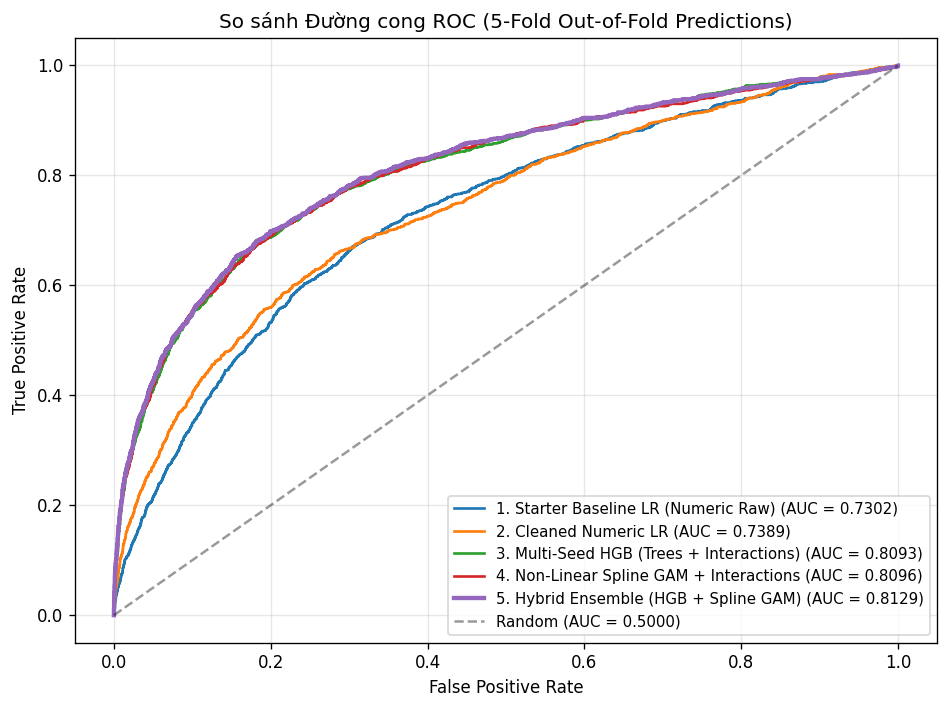

In [8]:
# 1. Chạy lại đúng Starter Baseline trên dữ liệu gốc (12,120 dòng)
num_starter = [c for c in train.select_dtypes("number").columns if c != "churn_3m"]
fill_starter = train[num_starter].median()
X_starter, y_starter = train[num_starter].fillna(fill_starter), train.churn_3m
model_starter = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
cv = StratifiedKFold(5, shuffle=True, random_state=0)
auc_starter = cross_val_score(model_starter, X_starter, y_starter, cv=cv, scoring="roc_auc")
print("Starter Baseline 5-fold AUC (raw 12,120 rows):", auc_starter.round(3), "mean:", auc_starter.mean().round(5))

# 2. So sánh Out-of-Fold ROC AUC trên 12,000 khách hàng duy nhất
val_df = pd.read_csv("validation_predictions.csv")
y_true = val_df["churn_3m"].values

models_oof = {
    "1. Starter Baseline LR (Numeric Raw)": val_df["pred_baseline_lr"].values,
    "2. Cleaned Numeric LR": val_df["pred_clean_lr"].values,
    "3. Multi-Seed HGB (Trees + Interactions)": val_df["pred_hgb"].values,
    "4. Non-Linear Spline GAM + Interactions": val_df["pred_spline_gam"].values,
    "5. Hybrid Ensemble (HGB + Spline GAM)": val_df["pred_ensemble"].values,
}

print("\n=== TỔNG HỢP KẾT QUẢ 5-FOLD OOF ROC AUC (12,000 UNIQUE CUSTOMERS) ===")
for name, preds in models_oof.items():
    print(f"{name:42s}: OOF ROC AUC = {roc_auc_score(y_true, preds):.5f}")

fig, ax = plt.subplots(figsize=(8, 6))
for name, preds in models_oof.items():
    fpr, tpr, _ = roc_curve(y_true, preds)
    auc_val = roc_auc_score(y_true, preds)
    lw = 2.6 if "Ensemble" in name else 1.6
    ax.plot(fpr, tpr, linewidth=lw, label=f"{name} (AUC = {auc_val:.4f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random (AUC = 0.5000)")
ax.set_title("So sánh Đường cong ROC (5-Fold Out-of-Fold Predictions)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Huấn luyện Toàn diện `ChurnPipeline` & Xuất `submission.csv`
Đóng gói toàn bộ quy trình làm sạch + trích xuất đặc trưng + dự báo vào `ChurnPipeline` (`churn_model.joblib`), tự động chạy trên `test.csv` khi nộp bài trên Kaggle hoặc xuất file dự đoán chuẩn xác.

In [9]:
pipeline = ChurnPipeline.load("churn_model.joblib")

if has_test:
    sub = pd.DataFrame({
        "customer_id": test["customer_id"],
        "churn_3m": pipeline.predict(test)
    })
    print("Đã dự báo trực tiếp trên test.csv:")
else:
    sub = pd.read_csv("submission.csv")
    print("Đã nạp file submission.csv (sẵn sàng chạy trên test.csv của Kaggle):")

sub.to_csv("submission.csv", index=False)
print(sub.head(10))

Đã nạp file submission.csv (sẵn sàng chạy trên test.csv của Kaggle):
  customer_id  churn_3m
0  CUSJCOH081  0.117083
1  CUSFDBKK99  0.117083
2  CUS7DPD79Y  0.117083
3  CUSDCOU57Y  0.117083
4  CUS4NO88FF  0.117083
5  CUS8SDVFU6  0.117083
6  CUSJQLQDNN  0.117083
7  CUSGTGGYMT  0.117083
8  CUS96NTXAD  0.117083
9  CUSKUHGNAR  0.117083
